In [1]:
import sys

print("Python executable:", sys.executable)

Python executable: c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\venv\Scripts\python.exe


In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File path management
from pathlib import Path

# Display plots inside notebook
%matplotlib inline

# Set visualization style
sns.set_style("whitegrid")

print("All EDA libraries imported successfully!")

All EDA libraries imported successfully!


In [3]:
# Define dataset path
data_path = Path("../data/processed/store_1_grocery_sales.csv")

# Check whether the file exists
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

# Load processed dataset
df = pd.read_csv(data_path, parse_dates=["date"])

print("Processed dataset loaded successfully!")

Processed dataset loaded successfully!


In [4]:
df.head()

,id,date,store_nbr,family,sales,onpromotion
0,12,2013-01-01,1,GROCERY I,0.0,0
1,1794,2013-01-02,1,GROCERY I,2652.0,0
2,3576,2013-01-03,1,GROCERY I,2121.0,0
3,5358,2013-01-04,1,GROCERY I,2056.0,0
4,7140,2013-01-05,1,GROCERY I,2216.0,0


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1684
Number of columns: 6


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1684 entries, 0 to 1683
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           1684 non-null   int64         
 1   date         1684 non-null   datetime64[us]
 2   store_nbr    1684 non-null   int64         
 3   family       1684 non-null   str           
 4   sales        1684 non-null   float64       
 5   onpromotion  1684 non-null   int64         
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 79.1 KB


In [7]:
df.describe()

,id,date,store_nbr,sales,onpromotion
count,1.684000e+03,1684,1684.0,1684.000000,1684.000000
mean,1.499565e+06,2015-04-24 08:27:04.703088,1.0,2223.172803,17.560570
min,1.200000e+01,2013-01-01 00:00:00,1.0,0.000000,0.000000
25%,7.497885e+05,2014-02-26 18:00:00,1.0,1873.500000,0.000000
50%,1.499565e+06,2015-04-24 12:00:00,1.0,2283.500000,6.000000
75%,2.249342e+06,2016-06-19 06:00:00,1.0,2649.000000,28.000000
max,2.999118e+06,2017-08-15 00:00:00,1.0,9065.000000,167.000000
std,8.665389e+05,NaN,0.0,779.285352,24.741069


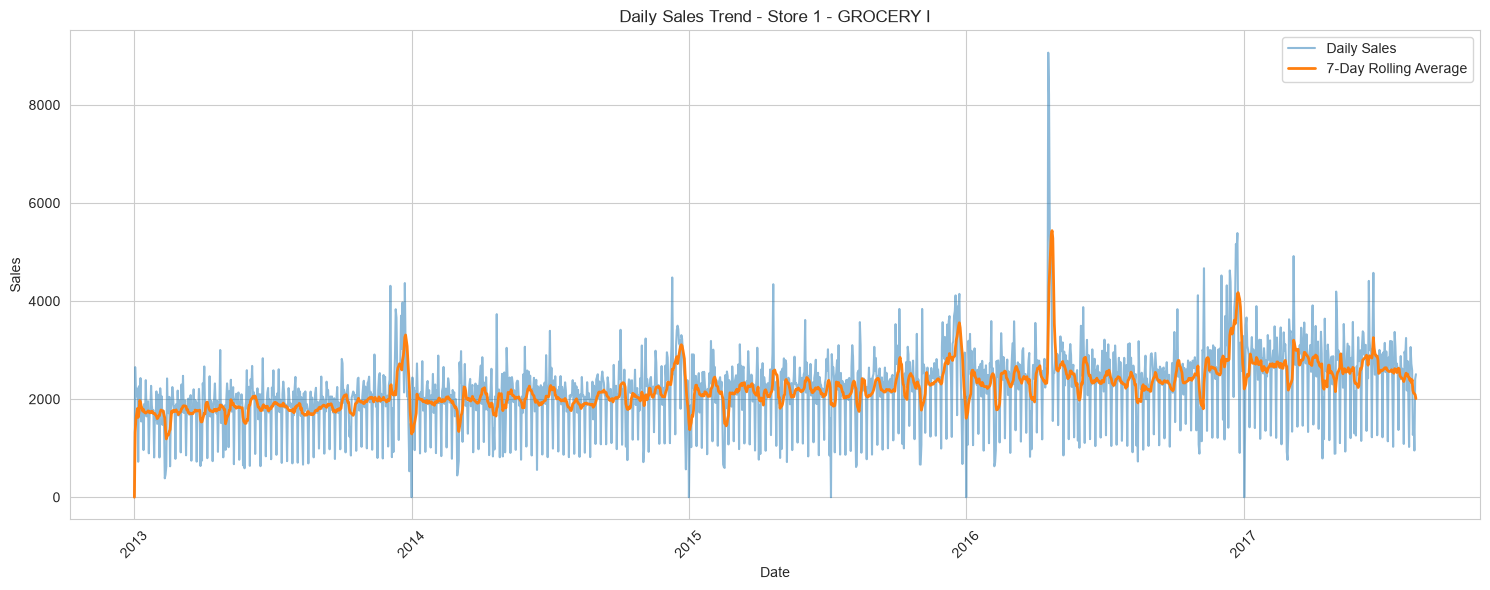

In [8]:
# Sort dataset by date
df = df.sort_values("date").copy()

# Set date as the DataFrame index
sales_df = df.set_index("date")

# Calculate 7-day rolling average
sales_df["sales_rolling_7"] = (
    sales_df["sales"].rolling(
        window="7D",
        min_periods=1
    ).mean()
)

# Create figure
plt.figure(figsize=(15, 6))

# Plot actual daily sales
plt.plot(
    sales_df.index,
    sales_df["sales"],
    label="Daily Sales",
    alpha=0.5
)

# Plot rolling average
plt.plot(
    sales_df.index,
    sales_df["sales_rolling_7"],
    label="7-Day Rolling Average",
    linewidth=2
)

# Add title and labels
plt.title("Daily Sales Trend - Store 1 - GROCERY I")
plt.xlabel("Date")
plt.ylabel("Sales")

# Add legend
plt.legend()

# Rotate date labels
plt.xticks(rotation=45)

# Adjust layout
plt.tight_layout()

# Display graph
plt.show()

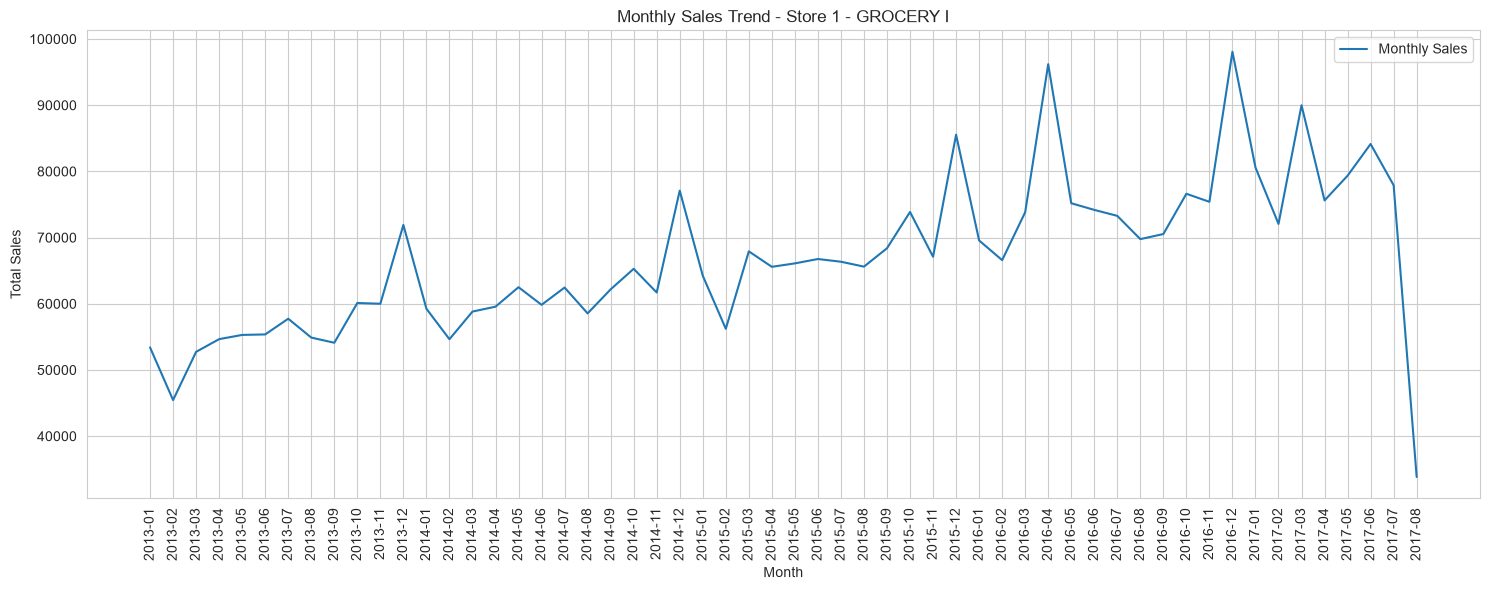

In [9]:
# Create a copy of the dataset
monthly_df = df.copy()

# Extract year and month from date
monthly_df["year_month"] = monthly_df["date"].dt.to_period("M")

# Calculate monthly total sales
monthly_sales = (
    monthly_df.groupby("year_month")["sales"]
    .sum()
)

# Create the visualization
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    label="Monthly Sales"
)

plt.title("Monthly Sales Trend - Store 1 - GROCERY I")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.legend()
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

### Monthly Sales Trend - Observations

1. Monthly sales generally show an increasing trend from 2013 to 2017.
2. Sales fluctuate across different months.
3. Several monthly sales peaks are visible during 2015–2017.
4. August 2017 has lower total sales because the dataset ends on August 15.
5. Monthly aggregation makes long-term sales patterns easier to understand.

year
2013    675641.0
2014    741844.0
2015    813668.0
2016    919204.0
2017    593466.0
Name: sales, dtype: float64


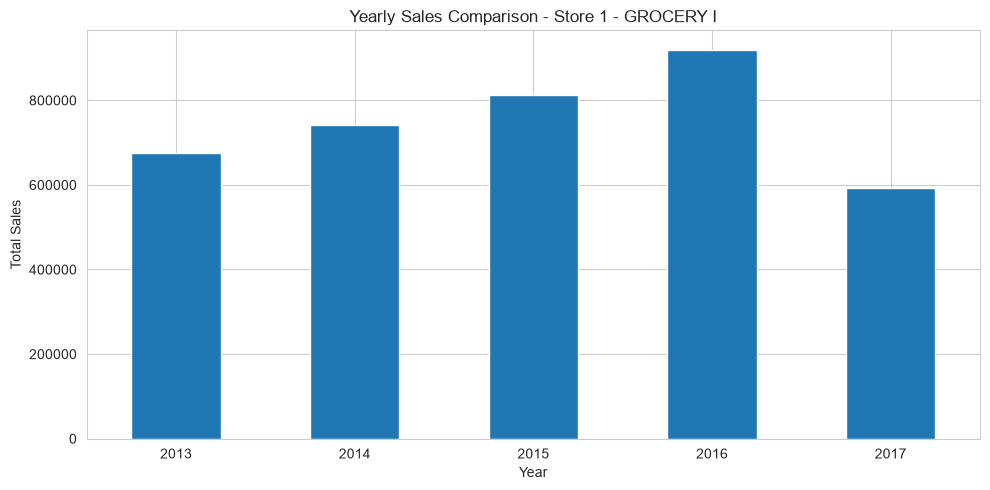

In [10]:
# Extract year from date
yearly_df = df.copy()

yearly_df["year"] = yearly_df["date"].dt.year

# Calculate yearly total sales
yearly_sales = (
    yearly_df.groupby("year")["sales"]
    .sum()
)

# Display yearly sales
print(yearly_sales)

# Visualize yearly sales
plt.figure(figsize=(10, 5))

yearly_sales.plot(kind="bar")

plt.title("Yearly Sales Comparison - Store 1 - GROCERY I")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Extract day of the week
selected_df["day_of_week"] = selected_df["date"].dt.day_name()

# Calculate average sales for each day
weekly_sales = selected_df.groupby(
    "day_of_week"
)["sales"].mean()

# Arrange days in calendar order
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_sales = weekly_sales.reindex(day_order)

# Display results
print("Average Sales by Day of Week:")
print(weekly_sales)

# Plot weekly sales
plt.figure(figsize=(10, 5))

weekly_sales.plot(kind="bar")

plt.title("Average Daily Sales by Weekday - Store 1 - GROCERY I")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'selected_df' is not defined

Average Daily Sales by Weekday:
day_of_week
Monday       2383.493776
Tuesday      2408.991736
Wednesday    2770.362500
Thursday     2229.045833
Friday       2413.645833
Saturday     2322.962656
Sunday       1031.075000
Name: sales, dtype: float64


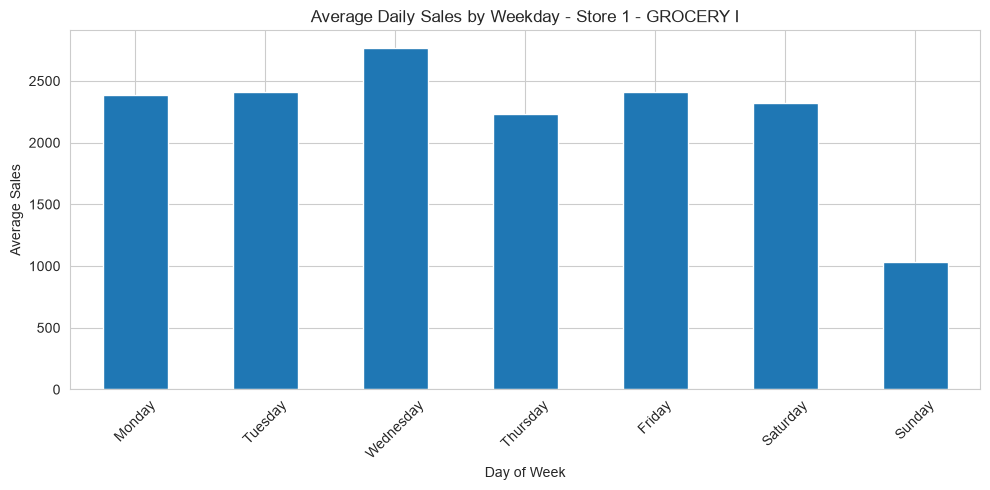

In [12]:
# Load the processed dataset
selected_df = pd.read_csv(
    "../data/processed/store_1_grocery_sales.csv",
    parse_dates=["date"]
)

# Extract day of the week
selected_df["day_of_week"] = selected_df["date"].dt.day_name()

# Calculate average sales for each day
weekly_sales = selected_df.groupby(
    "day_of_week"
)["sales"].mean()

# Arrange days in calendar order
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_sales = weekly_sales.reindex(day_order)

# Display results
print("Average Daily Sales by Weekday:")
print(weekly_sales)

# Create visualization
plt.figure(figsize=(10, 5))

weekly_sales.plot(kind="bar")

plt.title("Average Daily Sales by Weekday - Store 1 - GROCERY I")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Average Sales by Month:
month
1     2109.903226
2     2091.872340
3     2214.729032
4     2343.973333
5     2183.412903
6     2268.526667
7     2178.774194
8     2033.323741
9     2126.658333
10    2224.822581
11    2201.700000
12    2771.866667
Name: sales, dtype: float64


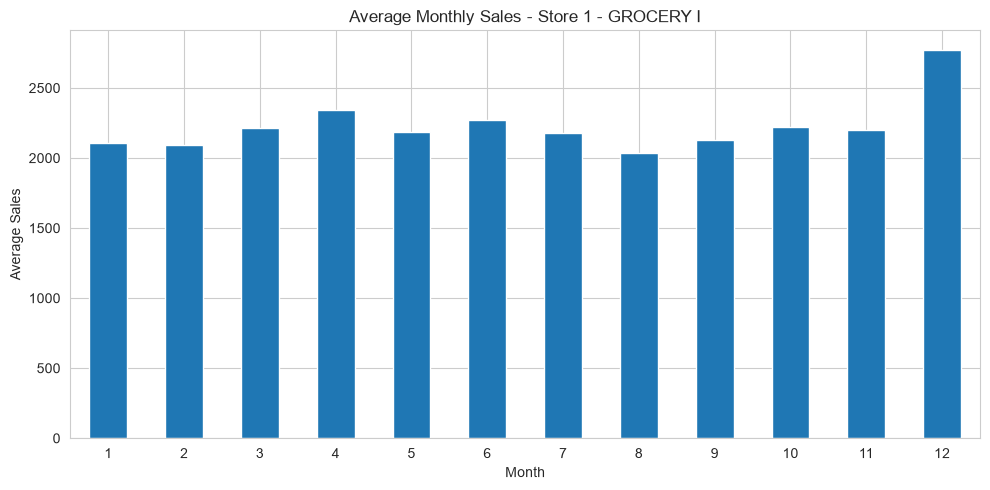

In [13]:
# Extract month number
selected_df["month"] = selected_df["date"].dt.month

# Calculate average sales for each month
monthly_average = selected_df.groupby(
    "month"
)["sales"].mean()

# Display results
print("Average Sales by Month:")
print(monthly_average)

# Create visualization
plt.figure(figsize=(10, 5))

monthly_average.plot(kind="bar")

plt.title("Average Monthly Sales - Store 1 - GROCERY I")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly Average Sales by Year:
year      2013     2014     2015     2016     2017
month                                             
1      1722.48  1911.19  2072.19  2243.90  2599.74
2      1623.11  1951.46  2007.68  2296.17  2573.64
3      1701.16  1897.32  2190.84  2381.35  2902.97
4      1821.80  1985.30  2186.03  3206.33  2520.40
5      1783.55  2016.13  2132.23  2425.45  2559.71
6      1845.47  1994.60  2225.30  2472.73  2804.53
7      1862.48  2014.45  2140.29  2363.81  2512.84
8      1770.65  1888.45  2116.45  2250.55  2254.87
9      1803.50  2072.63  2279.47  2351.03      NaN
10     1939.10  2105.77  2382.87  2471.55      NaN
11     2000.00  2056.70  2236.80  2513.30      NaN
12     2396.97  2569.77  2851.47  3269.27      NaN


<Figure size 1200x600 with 0 Axes>

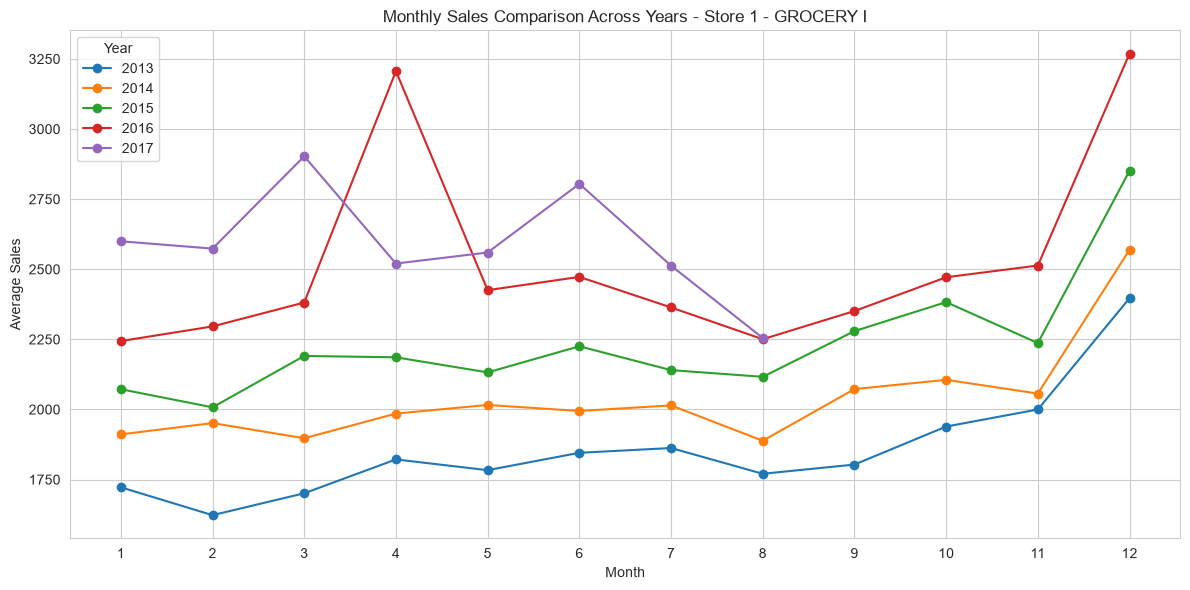

In [14]:
# Extract year and month
selected_df["year"] = selected_df["date"].dt.year
selected_df["month"] = selected_df["date"].dt.month

# Calculate monthly sales for each year
yearly_monthly_sales = selected_df.pivot_table(
    index="month",
    columns="year",
    values="sales",
    aggfunc="mean"
)

# Display the table
print("Monthly Average Sales by Year:")
print(yearly_monthly_sales.round(2))

# Plot the comparison
plt.figure(figsize=(12, 6))

yearly_monthly_sales.plot(
    marker="o",
    figsize=(12, 6)
)

plt.title("Monthly Sales Comparison Across Years - Store 1 - GROCERY I")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:

# Compare sales on promotion days and non-promotion days

selected_df["promotion_status"] = (
    selected_df["onpromotion"] > 0
)

promotion_analysis = selected_df.groupby(
    "promotion_status"
)["sales"].agg(
    ["mean", "median", "count"]
)

promotion_analysis.index = [
    "No Promotion",
    "Promotion"
]

print("Sales Comparison: Promotion vs No Promotion")
print(promotion_analysis)


Sales Comparison: Promotion vs No Promotion
                     mean  median  count
No Promotion  1873.156794  1965.0    574
Promotion     2404.172072  2454.5   1110


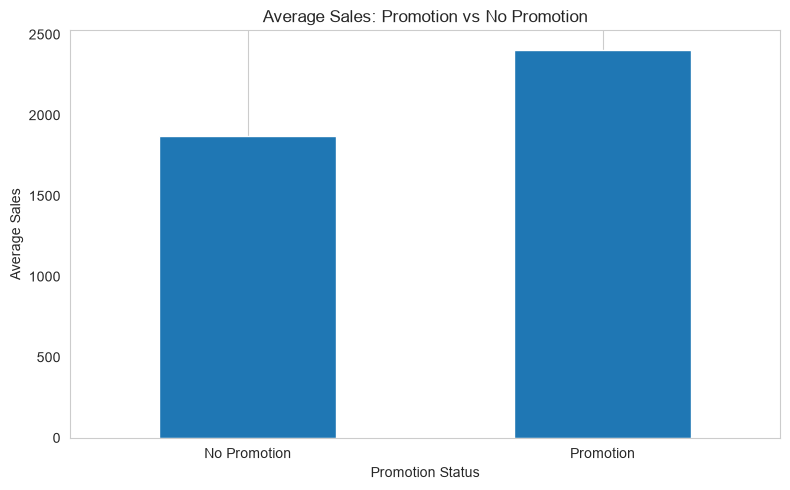

In [16]:

# Visualize average sales by promotion status

promotion_analysis["mean"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Sales: Promotion vs No Promotion")
plt.xlabel("Promotion Status")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [17]:

# Calculate correlation between promotion quantity and sales

correlation = selected_df[
    ["sales", "onpromotion"]
].corr()

print("Correlation between Sales and Promotion Quantity:")
print(correlation)

print("\nCorrelation coefficient:")
print(correlation.loc["sales", "onpromotion"])


Correlation between Sales and Promotion Quantity:
                sales  onpromotion
sales        1.000000     0.400343
onpromotion  0.400343     1.000000

Correlation coefficient:
0.4003432873517864


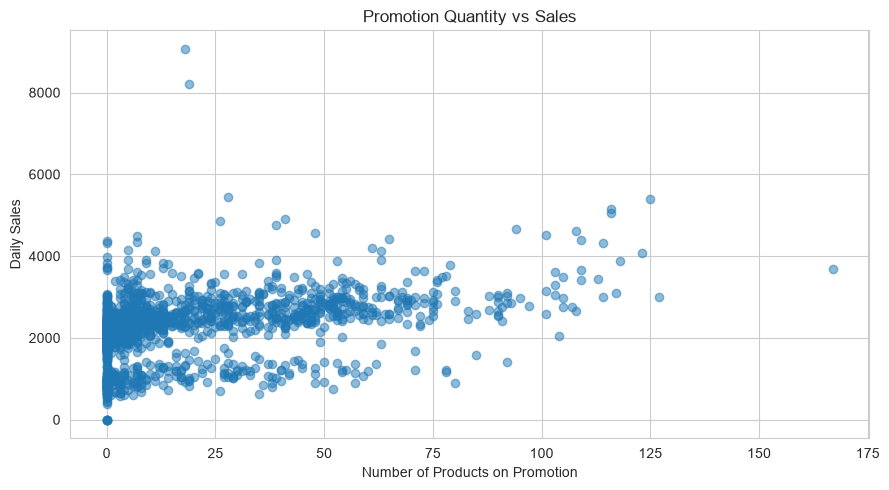

In [18]:

# Scatter plot: Promotion quantity vs Sales

plt.figure(figsize=(9, 5))

plt.scatter(
    selected_df["onpromotion"],
    selected_df["sales"],
    alpha=0.5
)

plt.title("Promotion Quantity vs Sales")
plt.xlabel("Number of Products on Promotion")
plt.ylabel("Daily Sales")

plt.grid(True)
plt.tight_layout()
plt.show()


In [19]:
# Analyze sales distribution

print("Sales Distribution Statistics:")
print(selected_df["sales"].describe())

# Calculate quartiles
Q1 = selected_df["sales"].quantile(0.25)
Q3 = selected_df["sales"].quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = selected_df[
    (selected_df["sales"] < lower_bound) |
    (selected_df["sales"] > upper_bound)
]

print("\nLower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nNumber of Outliers:", len(outliers))

print("\nHighest Sales Records:")
print(
    outliers.sort_values(
        by="sales",
        ascending=False
    )[["date", "sales", "onpromotion"]].head(10)
)

Sales Distribution Statistics:
count    1684.000000
mean     2223.172803
std       779.285352
min         0.000000
25%      1873.500000
50%      2283.500000
75%      2649.000000
max      9065.000000
Name: sales, dtype: float64

Lower Bound: 710.25
Upper Bound: 3812.25

Number of Outliers: 72

Highest Sales Records:
           date   sales  onpromotion
1200 2016-04-18  9065.0           18
1201 2016-04-19  8221.0           19
1202 2016-04-20  5438.0           28
1449 2016-12-23  5386.0          125
1447 2016-12-21  5162.0          116
1448 2016-12-22  5055.0          116
1522 2017-03-07  4917.0           41
1204 2016-04-22  4871.0           26
1203 2016-04-21  4768.0           39
1405 2016-11-09  4669.0           94


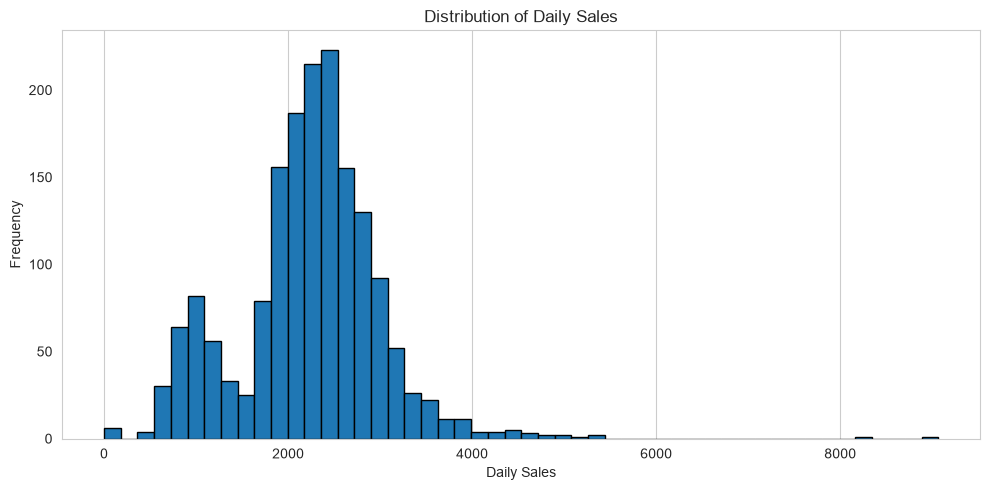

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(
    selected_df["sales"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Daily Sales")
plt.xlabel("Daily Sales")
plt.ylabel("Frequency")

plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [21]:
# Separate high and low outliers

high_outliers = selected_df[
    selected_df["sales"] > upper_bound
]

low_outliers = selected_df[
    selected_df["sales"] < lower_bound
]

print("High Outliers:", len(high_outliers))
print("Low Outliers:", len(low_outliers))

print("\nHigh Outlier Records:")
print(
    high_outliers[
        ["date", "sales", "onpromotion"]
    ].sort_values(
        by="sales",
        ascending=False
    ).head(15)
)

print("\nLow Outlier Records:")
print(
    low_outliers[
        ["date", "sales", "onpromotion"]
    ].sort_values(
        by="sales"
    ).head(15)
)

High Outliers: 36
Low Outliers: 36

High Outlier Records:
           date   sales  onpromotion
1200 2016-04-18  9065.0           18
1201 2016-04-19  8221.0           19
1202 2016-04-20  5438.0           28
1449 2016-12-23  5386.0          125
1447 2016-12-21  5162.0          116
1448 2016-12-22  5055.0          116
1522 2017-03-07  4917.0           41
1204 2016-04-22  4871.0           26
1203 2016-04-21  4768.0           39
1405 2016-11-09  4669.0           94
1439 2016-12-13  4624.0          108
1627 2017-06-20  4575.0           48
1428 2016-12-02  4522.0          101
707  2014-12-10  4481.0            7
1621 2017-06-14  4411.0           65

Low Outlier Records:
           date  sales  onpromotion
0    2013-01-01    0.0            0
915  2015-07-07    0.0            0
728  2015-01-01    0.0            0
364  2014-01-01    0.0            0
1457 2017-01-01    0.0            0
1092 2016-01-01    0.0            0
40   2013-02-10  385.0            0
424  2014-03-02  444.0            0
41  

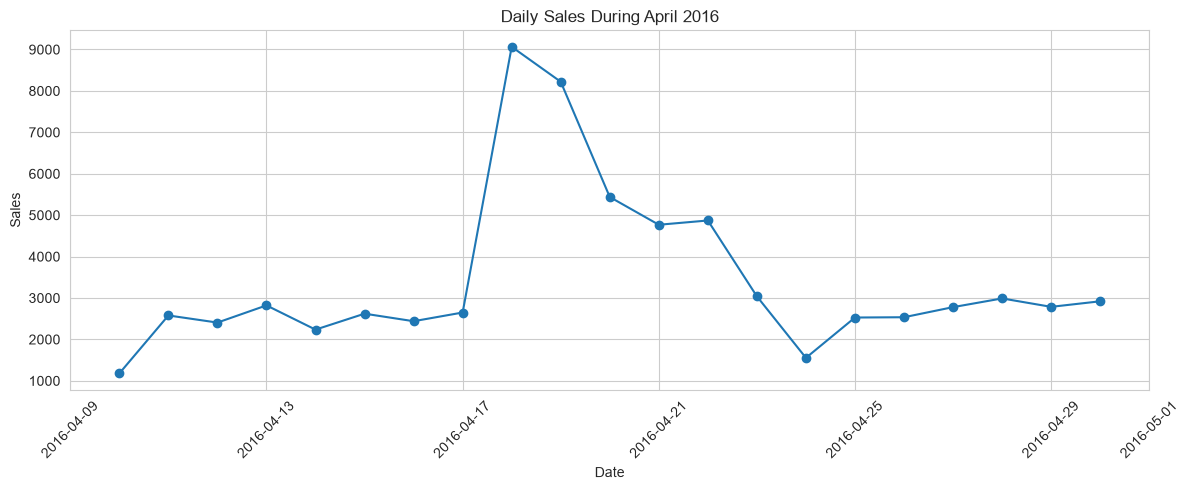

           date   sales  onpromotion
1192 2016-04-10  1179.0           31
1193 2016-04-11  2578.0           54
1194 2016-04-12  2406.0           54
1195 2016-04-13  2821.0           76
1196 2016-04-14  2236.0           13
1197 2016-04-15  2621.0           16
1198 2016-04-16  2439.0           22
1199 2016-04-17  2649.0           18
1200 2016-04-18  9065.0           18
1201 2016-04-19  8221.0           19
1202 2016-04-20  5438.0           28
1203 2016-04-21  4768.0           39
1204 2016-04-22  4871.0           26
1205 2016-04-23  3039.0           27
1206 2016-04-24  1554.0           34
1207 2016-04-25  2528.0           30
1208 2016-04-26  2535.0           33
1209 2016-04-27  2779.0           45
1210 2016-04-28  2989.0           63
1211 2016-04-29  2786.0           57
1212 2016-04-30  2920.0           69


In [22]:
# Investigate sales around April 2016

april_data = selected_df[
    (selected_df["date"] >= "2016-04-10") &
    (selected_df["date"] <= "2016-04-30")
]

plt.figure(figsize=(12, 5))

plt.plot(
    april_data["date"],
    april_data["sales"],
    marker="o"
)

plt.title("Daily Sales During April 2016")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

print(april_data[["date", "sales", "onpromotion"]])

In [23]:
# Compare April sales across different years

april_comparison = selected_df[
    selected_df["date"].dt.month == 4
].copy()

april_comparison["year"] = (
    april_comparison["date"].dt.year
)

april_yearly_stats = april_comparison.groupby("year")["sales"].agg(
    ["mean", "median", "max", "min", "count"]
)

print("April Sales Comparison Across Years:")
print(april_yearly_stats)

April Sales Comparison Across Years:
             mean  median     max     min  count
year                                            
2013  1821.800000  1863.0  3002.0   735.0     30
2014  1985.300000  2020.0  3733.0   815.0     30
2015  2186.033333  2280.5  4343.0   766.0     30
2016  3206.333333  2718.0  9065.0  1179.0     30
2017  2520.400000  2729.5  3912.0   790.0     30


<Figure size 1000x500 with 0 Axes>

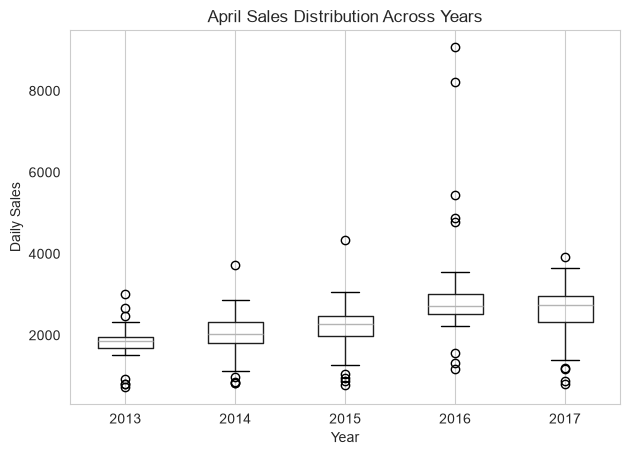

In [24]:
plt.figure(figsize=(10, 5))

april_comparison.boxplot(
    column="sales",
    by="year"
)

plt.title("April Sales Distribution Across Years")
plt.suptitle("")
plt.xlabel("Year")
plt.ylabel("Daily Sales")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

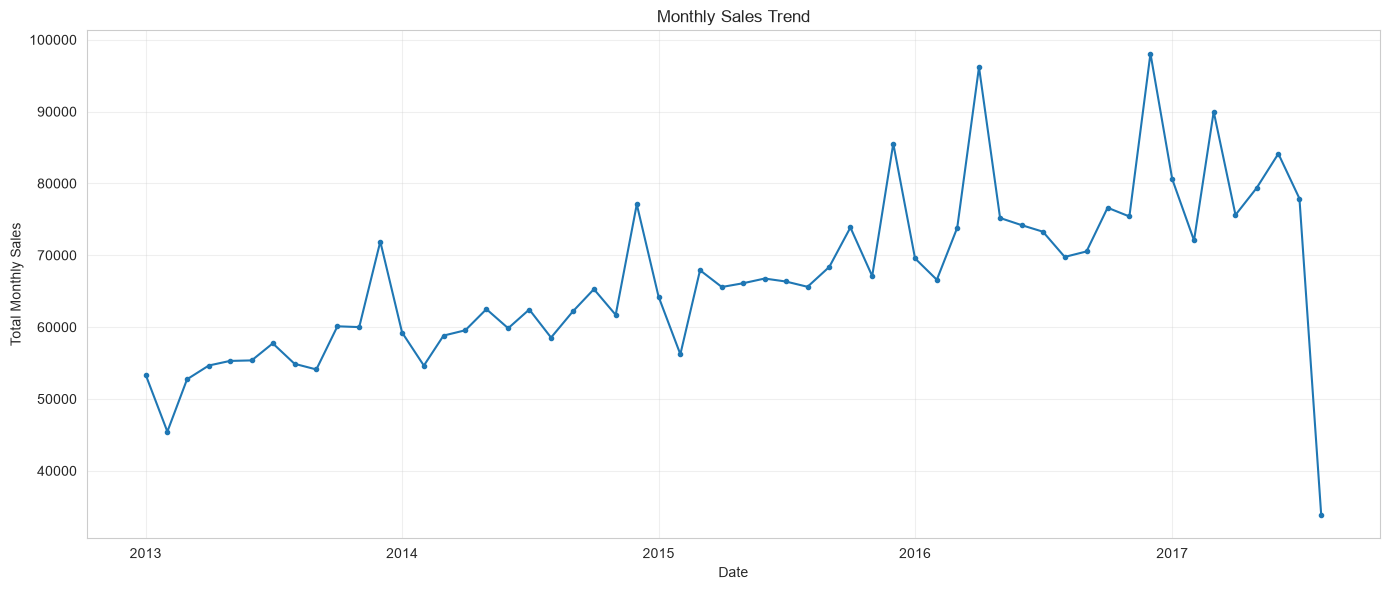

In [25]:
# Monthly sales trend

monthly_sales = (
    selected_df
    .set_index("date")["sales"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    markersize=3
)

plt.title("Monthly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Monthly Sales")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
# Highest and lowest sales months

monthly_summary = monthly_sales.sort_values(
    ascending=False
)

print("TOP 10 MONTHS BY SALES:")
print(monthly_summary.head(10))

print("\nBOTTOM 10 MONTHS BY SALES:")
print(monthly_summary.tail(10))

TOP 10 MONTHS BY SALES:
date
2016-12-01    98078.0
2016-04-01    96190.0
2017-03-01    89992.0
2015-12-01    85544.0
2017-06-01    84136.0
2017-01-01    80592.0
2017-05-01    79351.0
2017-07-01    77898.0
2014-12-01    77093.0
2016-10-01    76618.0
Name: sales, dtype: float64

BOTTOM 10 MONTHS BY SALES:
date
2013-06-01    55364.0
2013-05-01    55290.0
2013-08-01    54890.0
2013-04-01    54654.0
2014-02-01    54641.0
2013-09-01    54105.0
2013-01-01    53397.0
2013-03-01    52736.0
2013-02-01    45447.0
2017-08-01    33823.0
Name: sales, dtype: float64


In [27]:
# Monthly seasonality analysis

# Exclude August 2017 because it is incomplete
complete_months = monthly_sales[
    monthly_sales.index < "2017-08-01"
]

seasonal_sales = complete_months.groupby(
    complete_months.index.month
).agg(["mean", "median", "min", "max"])

seasonal_sales.index = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

print("MONTHLY SEASONALITY:")
print(seasonal_sales)

MONTHLY SEASONALITY:
               mean   median      min      max
January    65407.00  64238.0  53397.0  80592.0
February   58990.80  56215.0  45447.0  72062.0
March      68656.60  67916.0  52736.0  89992.0
April      70319.20  65581.0  54654.0  96190.0
May        67685.80  66099.0  55290.0  79351.0
June       68055.80  66759.0  55364.0  84136.0
July       67542.00  66349.0  57737.0  77898.0
August     62202.25  62076.0  54890.0  69767.0
September  63799.75  65281.5  54105.0  70531.0
October    68969.50  69574.0  60112.0  76618.0
November   66051.00  64402.5  60000.0  75399.0
December   83156.00  81318.5  71909.0  98078.0


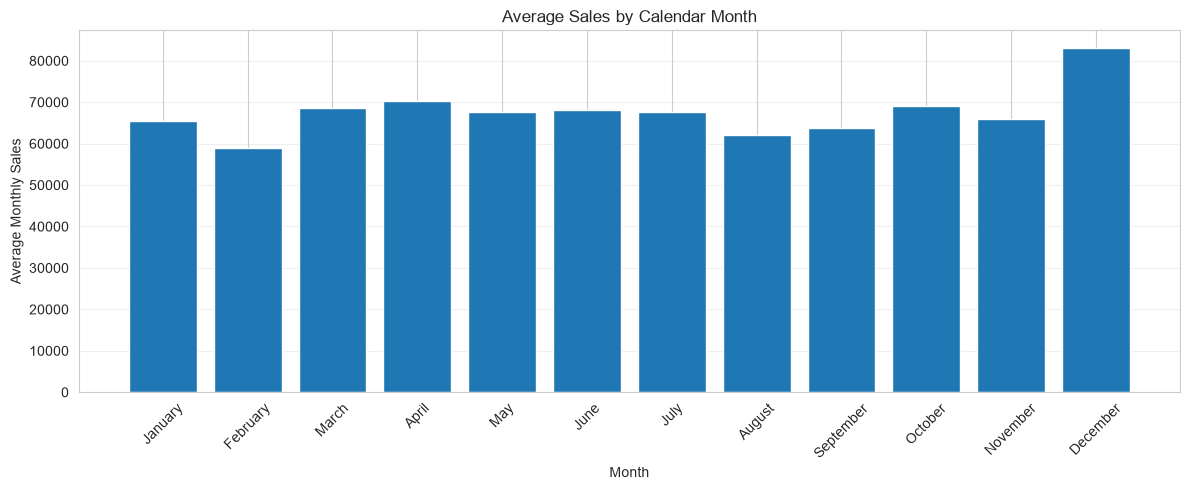

In [28]:
plt.figure(figsize=(12, 5))

plt.bar(
    seasonal_sales.index,
    seasonal_sales["mean"]
)

plt.title("Average Sales by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Monthly Sales")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:

# Weekday vs Weekend Sales Analysis

# Extract day of week
selected_df["day_of_week"] = selected_df["date"].dt.day_name()

# Identify weekdays and weekends
selected_df["day_type"] = selected_df["date"].dt.dayofweek.apply(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Compare sales
weekday_weekend_sales = selected_df.groupby("day_type")["sales"].agg(
    ["mean", "median", "min", "max", "count"]
)

print("WEEKDAY VS WEEKEND SALES:")
print(weekday_weekend_sales)


WEEKDAY VS WEEKEND SALES:
                 mean  median  min     max  count
day_type                                         
Weekday   2441.006650  2397.0  0.0  9065.0   1203
Weekend   1678.361746  1554.0  0.0  3912.0    481


C:\Users\Anshika Singh\AppData\Local\Temp\ipykernel_12828\3263583628.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  selected_df["day_type"] = selected_df["date"].dt.dayofweek.apply(


AVERAGE SALES BY DAY:
day_of_week
Monday       2383.493776
Tuesday      2408.991736
Wednesday    2770.362500
Thursday     2229.045833
Friday       2413.645833
Saturday     2322.962656
Sunday       1031.075000
Name: sales, dtype: float64


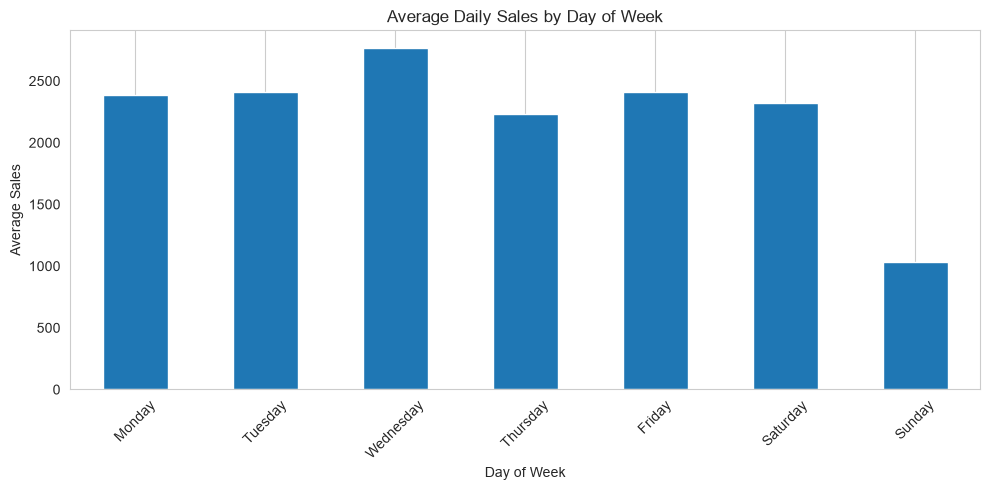

In [30]:

# Average Sales by Day of Week

weekday_sales = selected_df.groupby("day_of_week")["sales"].mean()

# Arrange days in calendar order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(day_order)

print("AVERAGE SALES BY DAY:")
print(weekday_sales)

# Visualization
plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Daily Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()


In [31]:

# Promotion Impact Analysis

# Create promotion category
selected_df["promotion_status"] = selected_df["onpromotion"].apply(
    lambda value: "Promotion" if value > 0 else "No Promotion"
)

# Compare sales
promotion_analysis = selected_df.groupby(
    "promotion_status"
)["sales"].agg(
    ["mean", "median", "min", "max", "count"]
)

print("SALES WITH AND WITHOUT PROMOTIONS:")
print(promotion_analysis)


SALES WITH AND WITHOUT PROMOTIONS:
                         mean  median    min     max  count
promotion_status                                           
No Promotion      1873.156794  1965.0    0.0  4367.0    574
Promotion         2404.172072  2454.5  568.0  9065.0   1110


In [32]:

# Relationship Between Promotions and Sales

correlation = selected_df["sales"].corr(
    selected_df["onpromotion"]
)

print("Correlation between Sales and Promotions:")
print(correlation)


Correlation between Sales and Promotions:
0.40034328735178637


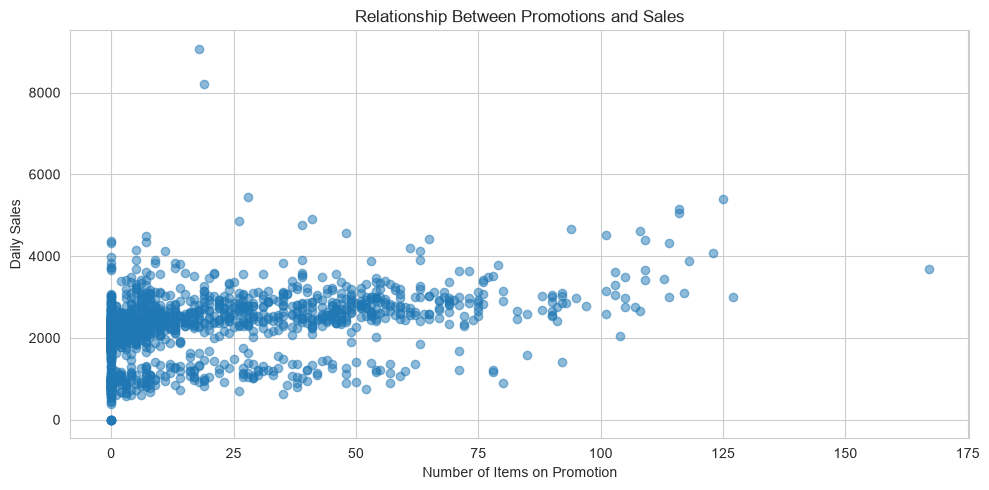

In [33]:

plt.figure(figsize=(10, 5))

plt.scatter(
    selected_df["onpromotion"],
    selected_df["sales"],
    alpha=0.5
)

plt.title("Relationship Between Promotions and Sales")
plt.xlabel("Number of Items on Promotion")
plt.ylabel("Daily Sales")
plt.grid(True)

plt.tight_layout()
plt.show()


In [34]:
# Outlier Analysis using IQR

Q1 = selected_df["sales"].quantile(0.25)
Q3 = selected_df["sales"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = selected_df[
    (selected_df["sales"] < lower_bound) |
    (selected_df["sales"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nNumber of Outliers:", len(outliers))

print("\nOutlier Records:")
print(outliers[["date", "sales", "onpromotion"]].head(20))

Q1: 1873.5
Q3: 2649.0
IQR: 775.5
Lower Bound: 710.25
Upper Bound: 3812.25

Number of Outliers: 72

Outlier Records:
          date   sales  onpromotion
0   2013-01-01     0.0            0
40  2013-02-10   385.0            0
41  2013-02-11   458.0            0
42  2013-02-12   628.0            0
47  2013-02-17   630.0            0
87  2013-03-29   636.0            0
131 2013-05-12   674.0            0
143 2013-05-24   650.0            0
145 2013-05-26   590.0            0
152 2013-06-02   639.0            0
166 2013-06-16   633.0            0
194 2013-07-14   699.0            0
208 2013-07-28   690.0            0
215 2013-08-04   704.0            0
222 2013-08-11   664.0            0
229 2013-08-18   689.0            0
337 2013-12-04  4311.0            0
344 2013-12-11  3833.0            0
353 2013-12-20  3972.0            0
356 2013-12-23  4367.0            0


C:\Users\Anshika Singh\AppData\Local\Temp\ipykernel_12828\4212120262.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(selected_df["sales"], vert=False)


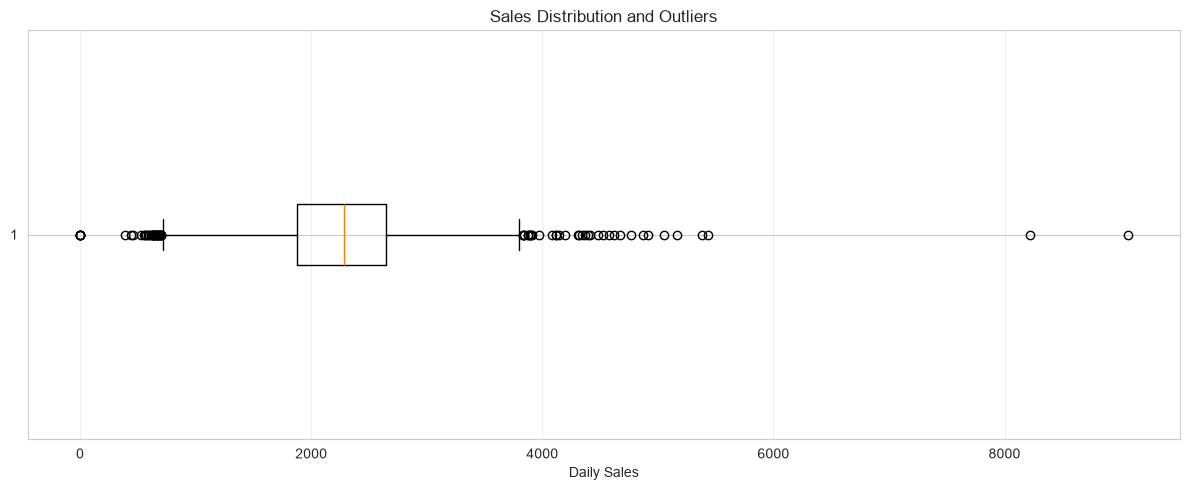

In [35]:
# Boxplot for Sales Outlier Detection

plt.figure(figsize=(12, 5))

plt.boxplot(selected_df["sales"], vert=False)

plt.title("Sales Distribution and Outliers")
plt.xlabel("Daily Sales")

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

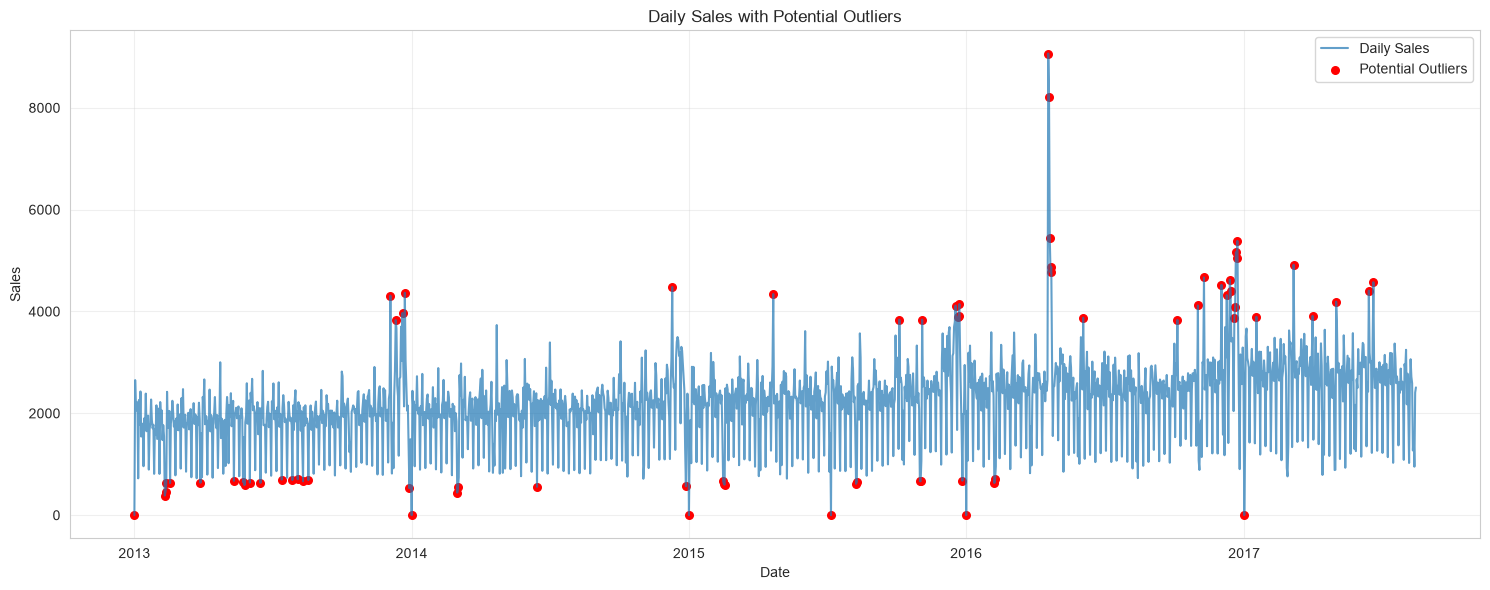

In [36]:
# Sales over time with outliers highlighted

plt.figure(figsize=(15, 6))

plt.plot(
    selected_df["date"],
    selected_df["sales"],
    label="Daily Sales",
    alpha=0.7
)

plt.scatter(
    outliers["date"],
    outliers["sales"],
    color="red",
    label="Potential Outliers",
    s=30
)

plt.title("Daily Sales with Potential Outliers")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Exploratory Data Analysis (EDA) — Final Findings

## 1. Dataset Overview
- Store: 1
- Product Family: GROCERY I
- Total records: 1,684
- Target variable: sales
- Date range: January 2013 to August 2017

## 2. Sales Distribution
- Average daily sales: approximately 2,223
- Median daily sales: 2,283.5
- Minimum sales: 0
- Maximum sales: 9,065

## 3. Time-Based Analysis
- Weekday sales are higher than weekend sales.
- Sunday has the lowest average daily sales.
- Sales show fluctuations over time.

## 4. Promotion Analysis
- Average sales without promotion: approximately 1,873
- Average sales with promotion: approximately 2,404
- Correlation between promotions and sales: approximately 0.4003

## 5. Outlier Analysis
- IQR method identified 72 potential outliers.
- Potential outliers include unusually low and high sales.
- Outliers will not be automatically removed.

## 6. EDA Conclusion
The dataset contains useful sales patterns, weekly variations,
promotion-related relationships, and unusual observations.

These findings will guide data preprocessing and feature engineering
in the next phase.
